In [3]:
%matplotlib widget

ValueError: Key backend: 'module://ipympl.backend_nbagg' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template', 'inline']

In [4]:
%matplotlib inline

In [5]:
import os
import matplotlib

print("Python version:", __import__("sys").version)
print("Matplotlib version:", matplotlib.__version__)
print("Matplotlib config:", matplotlib.matplotlib_fname())
print("Configured backend:", matplotlib.get_backend())
print("MPLBACKEND:", os.environ.get("MPLBACKEND"))

Python version: 3.9.6 (default, May 22 2026, 11:13:45) 
[Clang 21.0.0 (clang-2100.1.1.101)]
Matplotlib version: 3.9.4
Matplotlib config: /Users/HridyaSharma/Library/Python/3.9/lib/python/site-packages/matplotlib/mpl-data/matplotlibrc
Configured backend: module://matplotlib_inline.backend_inline
MPLBACKEND: module://matplotlib_inline.backend_inline


In [6]:
import os

print("MATPLOTLIBRC:", os.environ.get("MATPLOTLIBRC"))
print("MPLBACKEND:", os.environ.get("MPLBACKEND"))

from pathlib import Path

config_file = Path.home() / ".matplotlib" / "matplotlibrc"
print("User config exists:", config_file.exists())

if config_file.exists():
    print(config_file.read_text())

MATPLOTLIBRC: None
MPLBACKEND: module://matplotlib_inline.backend_inline
User config exists: False


In [7]:
%pip show ipympl%pip show ipympl

Note: you may need to restart the kernel to use updated packages.


In [8]:
%pip install ipympl

Defaulting to user installation because normal site-packages is not writeable
  Using cached ipympl-0.10.0-py3-none-any.whl.metadata (9.4 kB)
Using cached ipympl-0.10.0-py3-none-any.whl (519 kB)
Note: you may need to restart the kernel to use updated packages.


In [14]:
import numpy as np
%matplotlib widget
import matplotlib.pyplot as plt
from lab_utils_common import dlc, plot_data
from plt_one_addpt_onclick import plt_one_addpt_onclick
plt.style.use('./deeplearning.mplstyle')

In [15]:
import lab_utils_common

print(lab_utils_common.__file__)
print(dir(lab_utils_common))

/Users/HridyaSharma/Desktop/ML/regression-gradient descent/classification/lab_utils_common.py
['FancyArrowPatch', 'Output', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'compute_cost', 'compute_cost_logistic', 'compute_cost_matrix', 'compute_gradient', 'compute_gradient_matrix', 'copy', 'dlblue', 'dlc', 'dlcolors', 'dldarkred', 'dlmagenta', 'dlorange', 'dlpurple', 'draw_vthresh', 'gradient_descent', 'log_1pexp', 'math', 'np', 'plot_data', 'plt', 'plt_tumor_data', 'predict_linear', 'predict_logistic', 'sigmoid', 'zscore_normalize_features']


In [16]:
import os

print(os.getcwd())
print(os.listdir())

/Users/HridyaSharma/Desktop/ML/regression-gradient descent/classification
['plt_overfit.py', 'deeplearning.mplstyle', 'proj.ipynb', 'plt_quad_logistic.py', '.ipynb_checkpoints', 'lab_utils_uni.py', 'plt_logistic_loss.py', 'plt_one_addpt_onclick.py', 'lab_utils_multi.py', 'lab_utils_common.py']


In [17]:
from pathlib import Path

folder = Path.cwd()

for file in folder.glob("*.py"):
    content = file.read_text(errors="ignore")
    if "def plot_data" in content:
        print("Found in:", file)

Found in: /Users/HridyaSharma/Desktop/ML/regression-gradient descent/classification/lab_utils_common.py


In [18]:
from pathlib import Path

file = Path("lab_utils_common.py")
content = file.read_text()

for i, line in enumerate(content.splitlines(), start=1):
    if "plot_data" in line:
        print(f"Line {i}: {line}")

Line 243: def plot_data(X, y, ax, pos_label="y=1", neg_label="y=0", s=80, loc='best' ):


In [19]:
import importlib
import lab_utils_common

importlib.reload(lab_utils_common)

print(hasattr(lab_utils_common, "plot_data"))
print(dir(lab_utils_common))

True
['FancyArrowPatch', 'Output', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'compute_cost', 'compute_cost_logistic', 'compute_cost_matrix', 'compute_gradient', 'compute_gradient_matrix', 'copy', 'dlblue', 'dlc', 'dlcolors', 'dldarkred', 'dlmagenta', 'dlorange', 'dlpurple', 'draw_vthresh', 'gradient_descent', 'log_1pexp', 'math', 'np', 'plot_data', 'plt', 'plt_tumor_data', 'predict_linear', 'predict_logistic', 'sigmoid', 'zscore_normalize_features']


In [20]:
x_train = np.array([0., 1, 2, 3, 4, 5])
y_train = np.array([0,  0, 0, 1, 1, 1])
X_train2 = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y_train2 = np.array([0, 0, 0, 1, 1, 1])

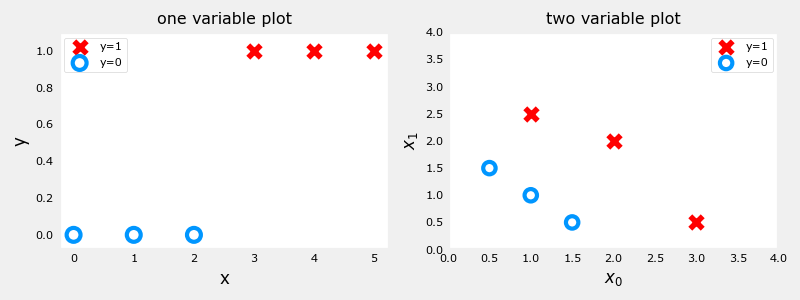

In [21]:
pos = y_train == 1
neg = y_train == 0

fig,ax = plt.subplots(1,2,figsize=(8,3))
#plot 1, single variable
ax[0].scatter(x_train[pos], y_train[pos], marker='x', s=80, c = 'red', label="y=1")
ax[0].scatter(x_train[neg], y_train[neg], marker='o', s=100, label="y=0", facecolors='none', 
              edgecolors=dlc["dlblue"],lw=3)

ax[0].set_ylim(-0.08,1.1)
ax[0].set_ylabel('y', fontsize=12)
ax[0].set_xlabel('x', fontsize=12)
ax[0].set_title('one variable plot')
ax[0].legend()

#plot 2, two variables
plot_data(X_train2, y_train2, ax[1])
ax[1].axis([0, 4, 0, 4])
ax[1].set_ylabel('$x_1$', fontsize=12)
ax[1].set_xlabel('$x_0$', fontsize=12)
ax[1].set_title('two variable plot')
ax[1].legend()
plt.tight_layout()
plt.show()


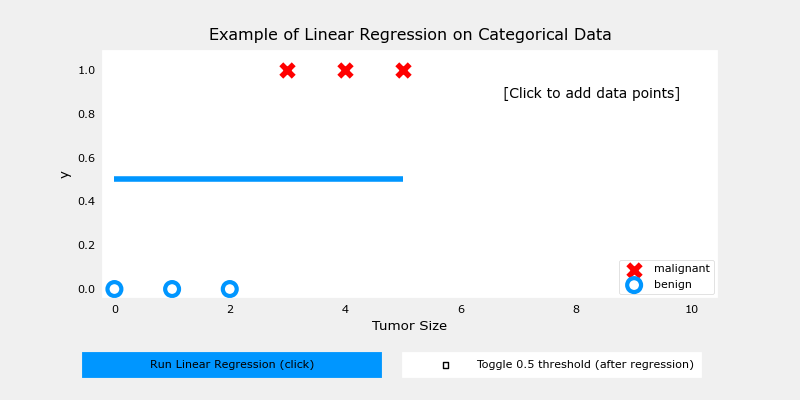

In [22]:
w_in = np.zeros((1))
b_in = 0
plt.close('all') 
addpt = plt_one_addpt_onclick( x_train,y_train, w_in, b_in, logistic=False)